# Démonstration Cartomize — Sentinel-2 L2A réel

**Objectif :** partir de vraies bandes téléchargées, contrôler leur provenance, lancer le prétraitement automatique, calculer des indices spectraux et produire des statistiques vérifiables.

Aucune image synthétique et aucun résultat prédéfini ne sont utilisés. L'identifiant exact de la scène est lu dans `data/provenance.json`.

> L'emprise est une fenêtre d'analyse située à Kinshasa et non une limite administrative.

## 1. Préparer l'environnement

Le dossier `data` est produit par `download_real_data.py`. Dans la version validée sur GitHub, les fichiers téléchargés et leurs SHA-256 sont conservés avec le tutoriel.

In [1]:
from pathlib import Path
import json, shutil
import numpy as np
import pandas as pd
import geopandas as gpd
import rasterio
from rasterio.mask import mask
import matplotlib.pyplot as plt
from IPython.display import display, Image as IPImage
import cartomize as cm

ROOT = Path.cwd()
if ROOT.name != "demonstration-carto":
    candidate = ROOT / "demonstration-carto"
    if candidate.is_dir():
        ROOT = candidate
DATA = ROOT / "data"
RESULTS = ROOT / "results"
if not (DATA / "provenance.json").is_file():
    raise FileNotFoundError("Données réelles absentes : exécuter download_real_data.py avant le notebook.")
if RESULTS.exists():
    shutil.rmtree(RESULTS)
RESULTS.mkdir()
provenance = json.loads((DATA / "provenance.json").read_text(encoding="utf-8"))
print("Scène :", provenance["selected_item_id"])
print("Date :", provenance["selected_datetime"])
print("Plateforme :", provenance["platform"])
print("Tuile MGRS :", provenance["mgrs_tile"])
print("Nuages déclarés :", provenance["global_cloud_cover_percent"], "%")
print("Pixels SCL utilisables sur l'emprise :", round(provenance["aoi_scl_usable_percent_before_processing"], 2), "%")

Scène : S2B_33MWR_20240720_0_L2A
Date : 2024-07-20T09:21:50.068000Z
Plateforme : sentinel-2b
Tuile MGRS : None
Nuages déclarés : 9.286346 %
Pixels SCL utilisables sur l'emprise : 99.95 %


## 2. Contrôler les fichiers avant traitement

On vérifie le CRS, la résolution, le type de pixel et les paramètres de calibration réellement déclarés dans le manifeste Cartomize.

In [2]:
scene = cm.load_scenes_manifest(DATA / "scenes.json")[0]
rows = []
for name, band in scene.bands.items():
    with rasterio.open(band.path) as src:
        rows.append({
            "bande": name,
            "fichier": Path(band.path).name,
            "largeur": src.width,
            "hauteur": src.height,
            "crs": str(src.crs),
            "resolution": src.res,
            "dtype": src.dtypes[0],
            "scale": band.scale,
            "offset": band.offset,
            "unite": band.unit,
        })
display(pd.DataFrame(rows))
print("Masque qualité :", Path(scene.quality).name, "|", scene.quality_kind)
print("Notes de calibration :")
for note in scene.notes:
    print("-", note)

,bande,fichier,largeur,hauteur,crs,resolution,dtype,scale,offset,unite
0,blue,B02.tif,667,664,EPSG:32733,"(10.0, 10.0)",uint16,0.0001,0.0,reflectance
1,green,B03.tif,667,664,EPSG:32733,"(10.0, 10.0)",uint16,0.0001,0.0,reflectance
2,red,B04.tif,667,664,EPSG:32733,"(10.0, 10.0)",uint16,0.0001,0.0,reflectance
3,nir,B08.tif,667,664,EPSG:32733,"(10.0, 10.0)",uint16,0.0001,0.0,reflectance
4,swir1,B11.tif,334,332,EPSG:32733,"(20.0, 20.0)",uint16,0.0001,0.0,reflectance


Masque qualité : SCL.tif | sentinel_scl
Notes de calibration :
- Earth Search COG harmonisé blue : scale déclaré=0.0001, offset déclaré=-0.1, offset effectif=0 ; earthsearch:boa_offset_applied=true, aucune seconde application du décalage BOA.
- Earth Search COG harmonisé green : scale déclaré=0.0001, offset déclaré=-0.1, offset effectif=0 ; earthsearch:boa_offset_applied=true, aucune seconde application du décalage BOA.
- Earth Search COG harmonisé red : scale déclaré=0.0001, offset déclaré=-0.1, offset effectif=0 ; earthsearch:boa_offset_applied=true, aucune seconde application du décalage BOA.
- Earth Search COG harmonisé nir : scale déclaré=0.0001, offset déclaré=-0.1, offset effectif=0 ; earthsearch:boa_offset_applied=true, aucune seconde application du décalage BOA.
- Earth Search COG harmonisé swir16 : scale déclaré=0.0001, offset déclaré=-0.1, offset effectif=0 ; earthsearch:boa_offset_applied=true, aucune seconde application du décalage BOA.


## 3. Prétraitement automatique

Cartomize contrôle la couverture, applique la calibration déclarée, utilise la couche SCL, harmonise les grilles et découpe sur la zone d'étude. Le seuil de démonstration est fixé à 95 % avant de connaître le résultat final.

In [3]:
prepared = cm.preprocess_imagery(
    DATA,
    RESULTS / "preprocessed",
    aoi=DATA / "aoi.geojson",
    band_order=["blue", "green", "red", "nir", "swir1"],
    coverage_threshold=95,
    allow_partial=False,
    mask_clouds=True,
    mask_saturation=False,
    multiband=True,
    separate_bands=True,
    composition="natural",
)
print("Statut :", prepared.report["status"])
print("Scènes retenues :", prepared.report["selected_scene_ids"])
print("Couverture utile :", round(prepared.report["usable_percent"], 3), "%")
print("Mosaïque :", prepared.report["mosaic"])
print("Rapport :", prepared.manifest)
product = prepared.products[0]
display(pd.DataFrame([product]))

Statut : partial
Scènes retenues : ['S2B_33MWR_20240720_0_L2A']
Couverture utile : 99.953 %
Mosaïque : False
Rapport : /home/runner/work/cartomize-python/cartomize-python/demonstration-carto/results/preprocessed/preprocessing.json


,scenes,multiband,bands,composition,source_index,report
0,[S2B_33MWR_20240720_0_L2A],/home/runner/work/cartomize-python/cartomize-p...,"{'1': {'name': 'blue', 'path': '/home/runner/w...",/home/runner/work/cartomize-python/cartomize-p...,/home/runner/work/cartomize-python/cartomize-p...,/home/runner/work/cartomize-python/cartomize-p...


## 4. Composition en couleurs naturelles

La composition est un produit de visualisation. Les analyses suivantes utilisent toujours le raster scientifique multibande.

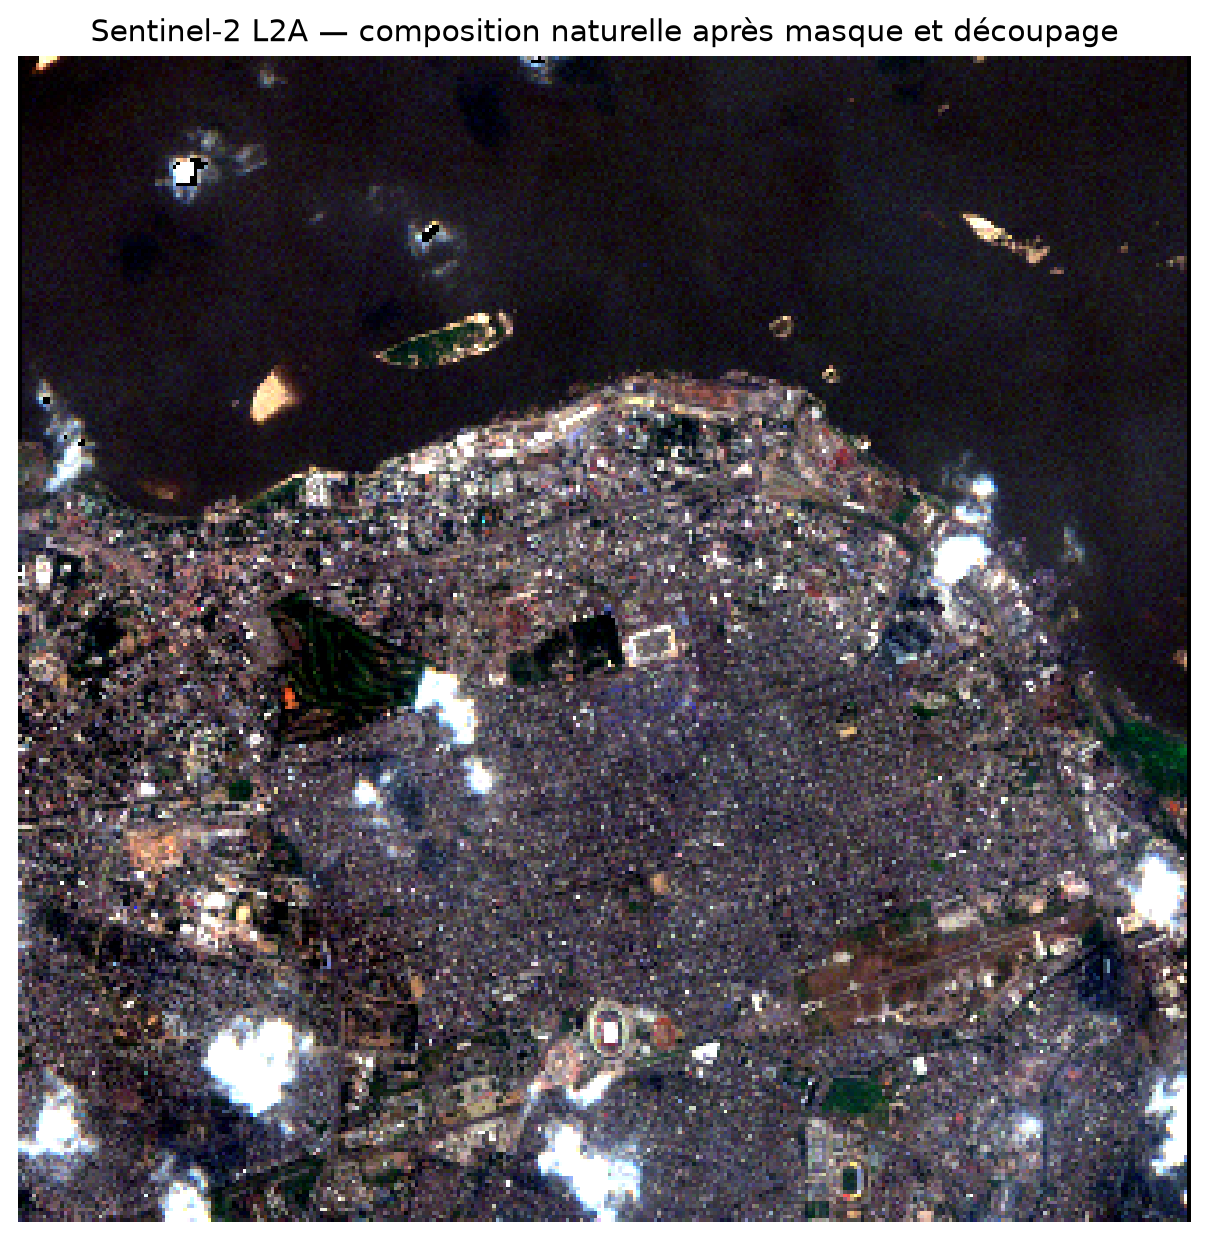

In [4]:
composition = Path(product["composition"])
with rasterio.open(composition) as src:
    rgb = np.moveaxis(src.read()[:3], 0, -1)
fig, ax = plt.subplots(figsize=(10, 7))
ax.imshow(rgb)
ax.set_title("Sentinel-2 L2A — composition naturelle après masque et découpage")
ax.axis("off")
fig.tight_layout()
fig.savefig(RESULTS / "natural_color.png", dpi=180, bbox_inches="tight")
plt.close(fig)
display(IPImage(filename=str(RESULTS / "natural_color.png")))

## 5. Calculs d’indices dans le notebook

Dans le notebook, nous calculons directement trois indices sur les vraies bandes préparées par Cartomize :

- **NDVI** — végétation ;
- **NDBI** — bâti / surfaces minérales, grâce à la bande SWIR1 (B11) ;
- **EVI** — végétation améliorée.

Ces trois calculs servent uniquement à montrer ce que l’on peut faire en mode notebook. Dans l’interface graphique, l’utilisateur reste libre de choisir l’indice qu’il souhaite calculer.

In [5]:
selected_indices = ["NDVI", "NDBI", "EVI"]

catalog = pd.DataFrame(cm.list_indices())
selected_catalog = catalog[catalog["name"].isin(selected_indices)][["name","title","bands","formula","domain","reference"]]
display(selected_catalog)

available_bands = {"blue", "green", "red", "nir", "swir1"}
for name in selected_indices:
    required = set(cm.get_index(name).bands)
    missing = sorted(required - available_bands)
    if missing:
        raise ValueError(f"{name} impossible : bandes absentes {missing}")
print("Indices calculés dans le notebook :", ", ".join(selected_indices))

,name,title,bands,formula,domain,reference
0,NDVI,Indice de végétation par différence normalisée,"(nir, red)",(nir-red)/(nir+red),Végétation,https://ntrs.nasa.gov/citations/19740022614
1,EVI,Indice de végétation amélioré,"(nir, red, blue)",g*(nir-red)/(nir+C1*red-C2*blue+L),Végétation,https://doi.org/10.1016/S0034-4257(96)00112-5
13,NDBI,Indice du bâti par différence normalisée,"(swir1, nir)",(swir1-nir)/(swir1+nir),Bâti,https://doi.org/10.1080/01431160304987


Indices calculés dans le notebook : NDVI, NDBI, EVI


## 6. Calcul et statistiques

Cartomize calcule NDVI, NDBI et EVI dans un raster multibande, puis produit des statistiques sur les pixels valides de chaque indice.

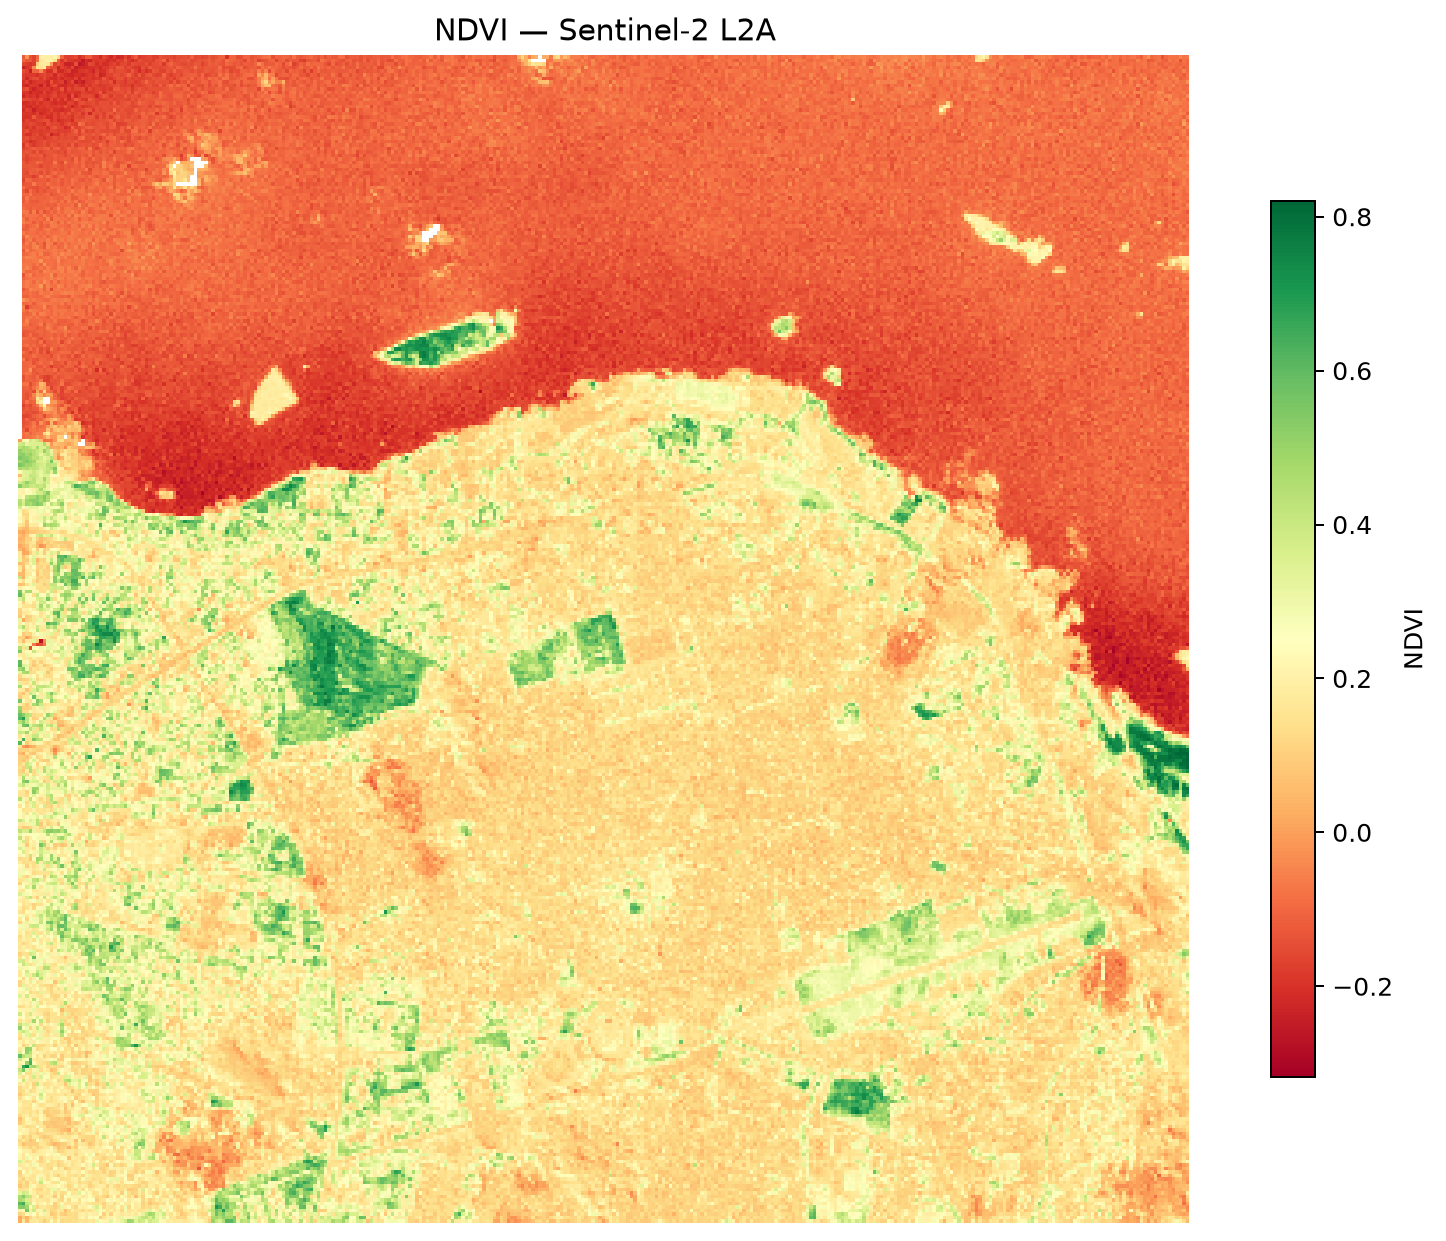

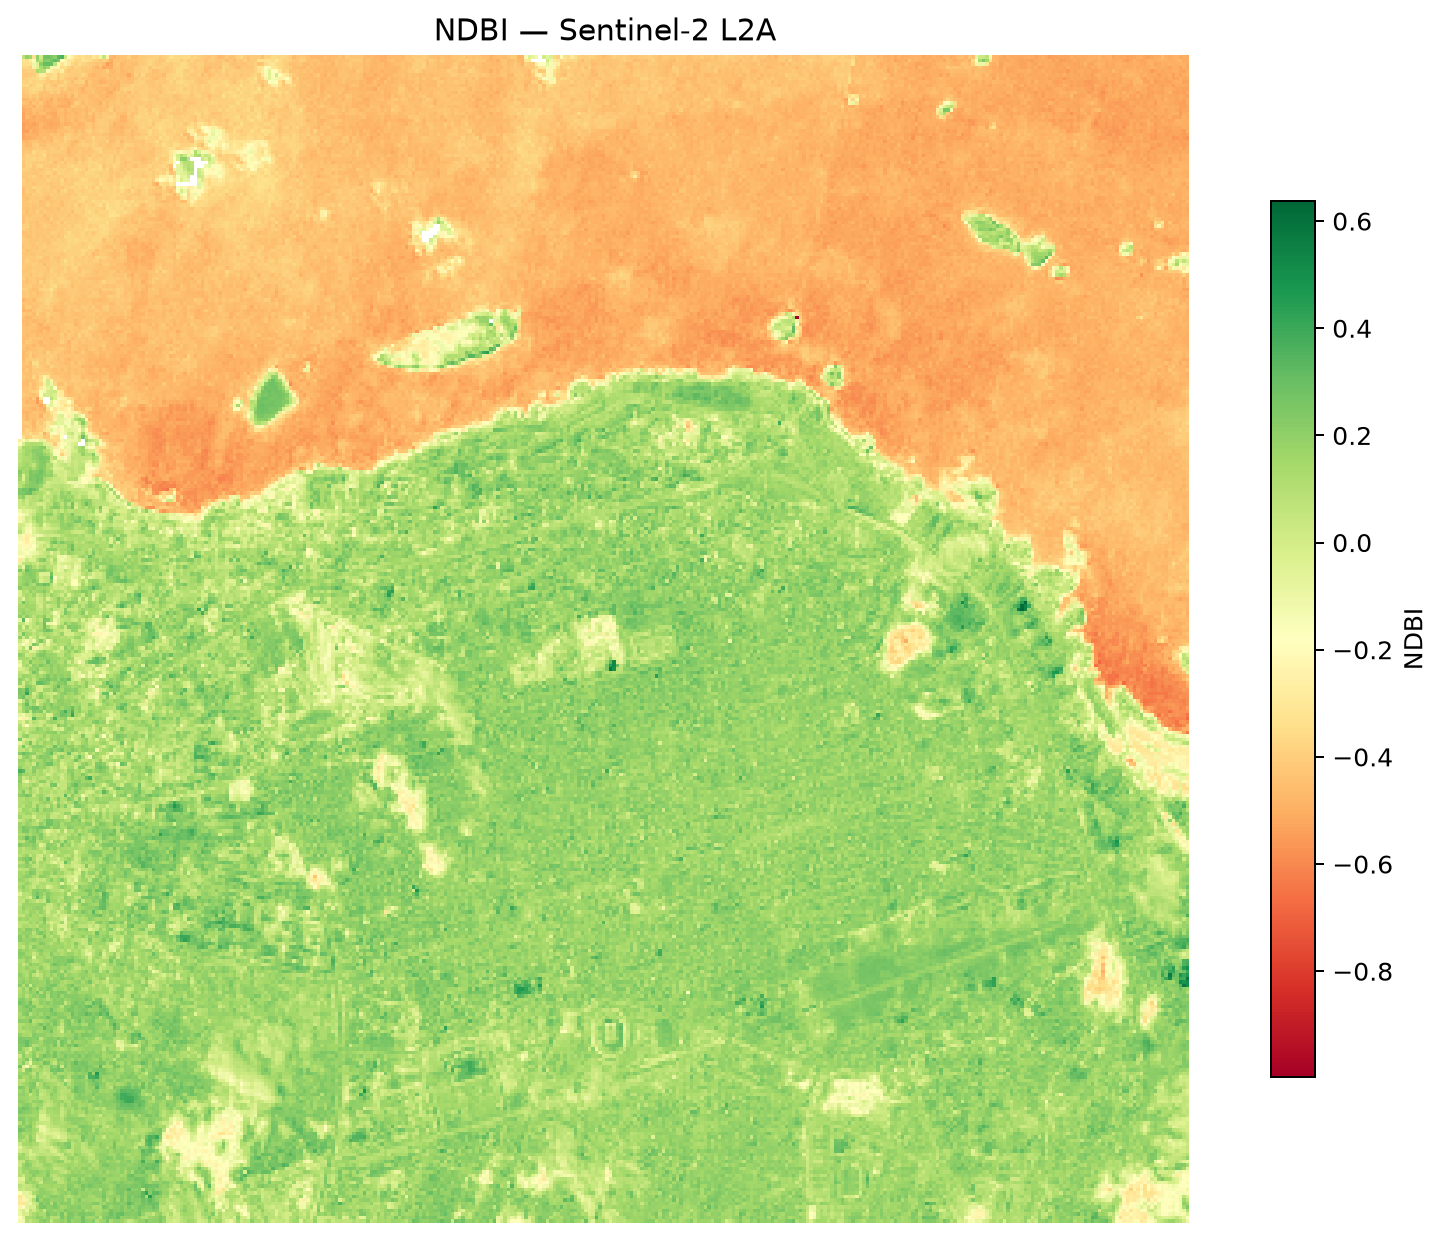

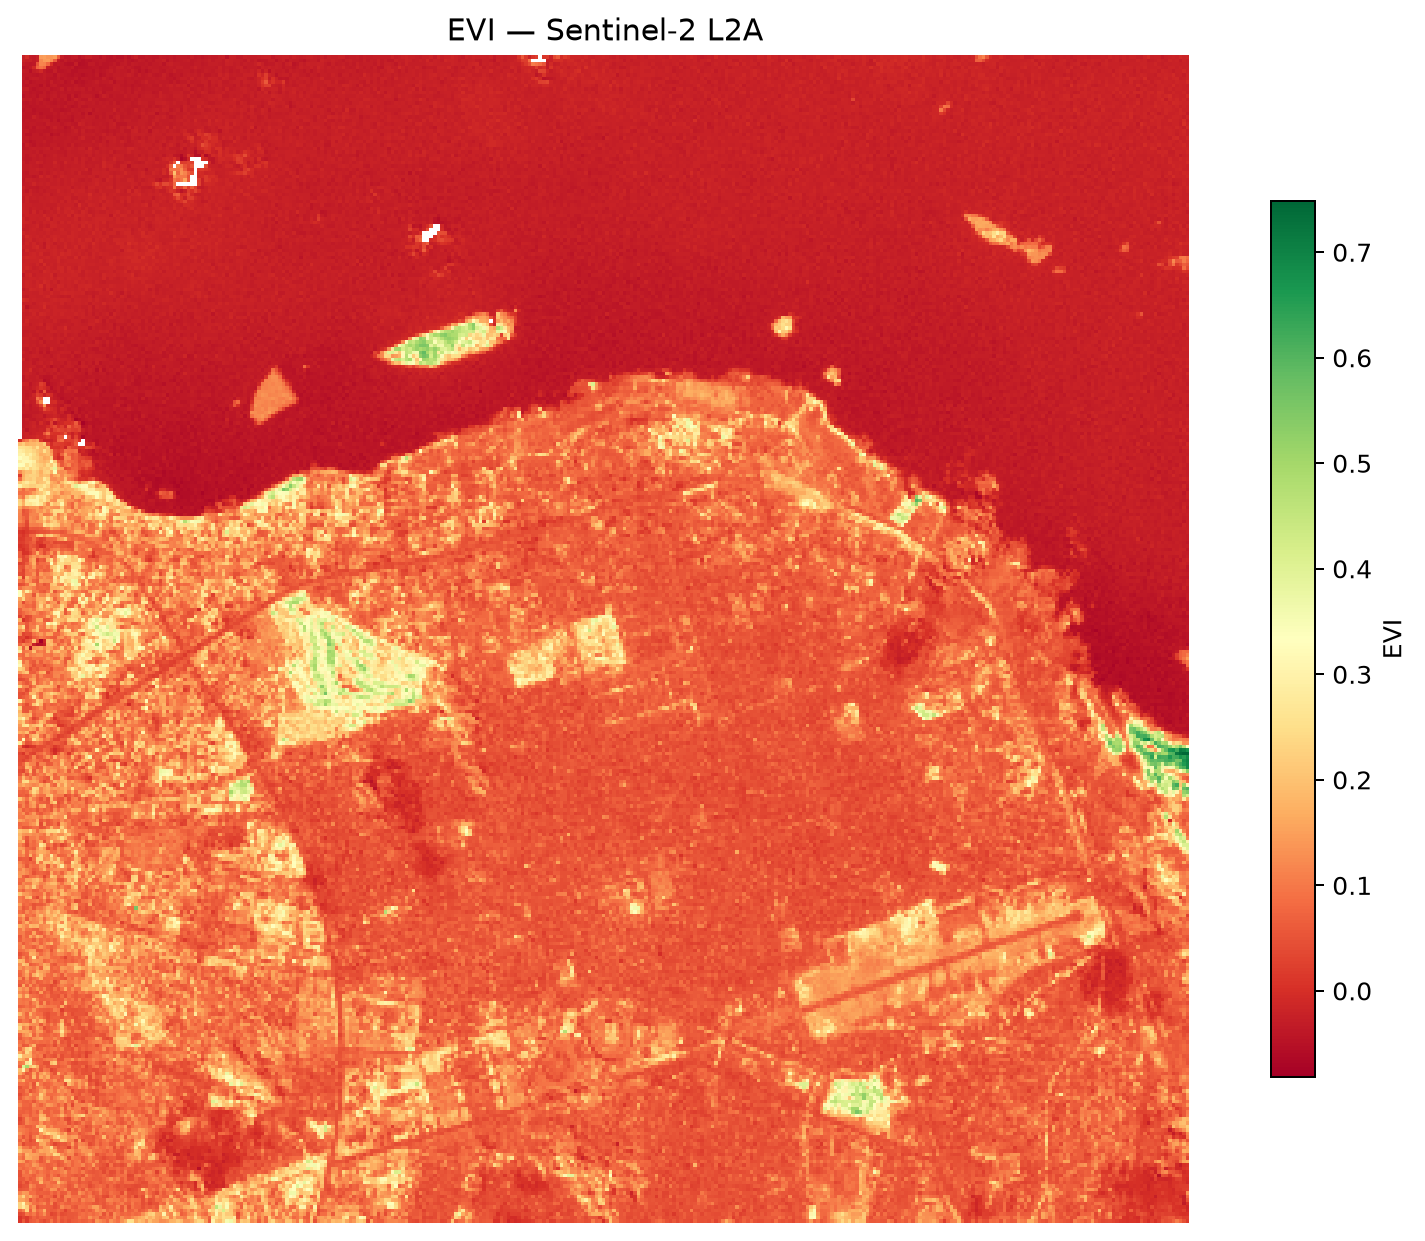

,count,min,max,mean,std,p05,p50,p95
NDVI,110395.0,-0.318021,0.819951,0.090796,0.186413,-0.161518,0.114286,0.429067
NDBI,110395.0,-0.997528,0.636833,-0.071257,0.300610,-0.518235,0.091248,0.249234
EVI,110395.0,-0.081684,0.748224,0.053763,0.085166,-0.039047,0.050370,0.210872


In [6]:
indices_path = cm.spectral_indices(
    product["multiband"],
    RESULTS / "indices.tif",
    indices=selected_indices,
)

index_stats = {}
index_images = {}

with rasterio.open(indices_path) as src:
    if tuple(src.descriptions) != tuple(selected_indices):
        raise RuntimeError("L'ordre des bandes d'indices ne correspond pas au choix demandé.")

    for band, name in enumerate(src.descriptions, 1):
        data = src.read(band, masked=True).astype("float64")
        valid = data.compressed()
        if not valid.size:
            raise RuntimeError(f"Aucun pixel valide pour {name}.")

        index_stats[name] = {
            "count": int(valid.size),
            "min": float(valid.min()),
            "max": float(valid.max()),
            "mean": float(valid.mean()),
            "std": float(valid.std()),
            "p05": float(np.quantile(valid, .05)),
            "p50": float(np.quantile(valid, .50)),
            "p95": float(np.quantile(valid, .95)),
        }

        image_name = name.lower() + ".png"
        index_images[name] = image_name

        fig, ax = plt.subplots(figsize=(9, 7))
        view = ax.imshow(data, cmap="RdYlGn")
        ax.set_title(f"{name} — Sentinel-2 L2A")
        ax.axis("off")
        fig.colorbar(view, ax=ax, shrink=.75, label=name)
        fig.tight_layout()
        fig.savefig(RESULTS / image_name, dpi=180, bbox_inches="tight")
        plt.close(fig)
        display(IPImage(filename=str(RESULTS / image_name)))

stats_df = pd.DataFrame(index_stats).T
stats_df.to_csv(RESULTS / "indices_stats.csv", encoding="utf-8-sig")
display(stats_df)


## 7. Résumé de l'automatisation

Le résultat central de la démonstration n'est pas un indice particulier : c'est la chaîne automatique.

**Bandes téléchargées → contrôle de cohérence → contrôle de couverture → masque qualité → découpage sur la zone d'étude → mosaïque si plusieurs scènes sont nécessaires → raster scientifique multibande → composite → indices choisis → statistiques.**

Le rapport ci-dessous conserve la décision prise par Cartomize et les produits effectivement générés.

In [7]:
metrics = {
    "schema": "cartomize.demonstration.automation.v2",
    "scene": {
        "id": provenance["selected_item_id"],
        "datetime": provenance["selected_datetime"],
        "platform": provenance["platform"],
        "global_cloud_cover_percent": provenance["global_cloud_cover_percent"],
    },
    "preprocessing": {
        "status": prepared.report["status"],
        "usable_percent": float(prepared.report["usable_percent"]),
        "threshold_met": bool(prepared.report["threshold_met"]),
        "selected_scene_ids": prepared.report["selected_scene_ids"],
        "mosaic": bool(prepared.report["mosaic"]),
        "band_order": prepared.report["parameters"]["band_order"],
        "resolution_m": prepared.report["parameters"]["resolution_m"],
        "crs": prepared.report["parameters"]["crs"],
    },
    "selected_indices": selected_indices,
    "indices": index_stats,
    "products": {
        "multiband": str(Path(product["multiband"]).relative_to(RESULTS / "preprocessed")),
        "composition": str(Path(product["composition"]).relative_to(RESULTS / "preprocessed")),
        "indices": "indices.tif",
        "statistics": "indices_stats.csv",
        "images": index_images,
    },
}
(RESULTS / "metrics.json").write_text(
    json.dumps(metrics, indent=2, ensure_ascii=False),
    encoding="utf-8",
)
display(pd.DataFrame([metrics["preprocessing"]]))

,status,usable_percent,threshold_met,selected_scene_ids,mosaic,band_order,resolution_m,crs
0,partial,99.952919,True,[S2B_33MWR_20240720_0_L2A],False,"[blue, green, red, nir, swir1]",20.0,"PROJCS[""WGS 84 / UTM zone 33S"",GEOGCS[""WGS 84""..."


## 8. Classification : seulement si l'utilisateur fournit des ROI

La classification n'est pas exécutée dans cette démonstration.

Elle reste disponible comme étape **optionnelle** : l'utilisateur peut créer des régions d'intérêt (ROI), les exporter avec leurs classes, puis fournir ces échantillons à Cartomize pour l'apprentissage et la classification. Pour une évaluation scientifique, un jeu de validation indépendant doit être fourni.

Ainsi, la démonstration principale reste centrée sur l'automatisation du prétraitement et des analyses raster.

## 9. Passage à l’interface graphique

Dans l’interface graphique, le prétraitement produit d’abord les bandes préparées, le raster scientifique multibande et le composite. Ensuite seulement, l’utilisateur ouvre **Indices spectraux**, sélectionne lui-même l’indice désiré et clique **Exécuter**.